# Known Boundary Values: Theory, Practice, and the sesmax API

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/inhomogeneous_bcs_tutorial.ipynb)

This tutorial builds inhomogeneous Dirichlet boundary conditions for elliptic solves **from scratch** — continuous mathematics, the discrete linear system, pseudocode, a hand-written NumPy implementation — and then shows how the same algorithm is packaged in sesmax.  Every claim made along the way is checked numerically in the cell that follows it.

**The problem.**  Given a right-hand side $f$ and prescribed boundary data $g$, find $\psi$ with

$$ (\nabla^2 - \lambda)\,\psi = f \quad \text{in } \Omega, \qquad \psi = g \quad \text{on } \partial\Omega, \qquad \lambda \ge 0 . $$

This one equation covers streamfunction inversion ($\lambda = 0$, $f = \zeta$), pressure recovery, and quasi-geostrophic PV inversion ($\lambda = 1/L_d^2$, $f = q$).  "Inhomogeneous" means $g \ne 0$: the boundary carries data — SSH from a parent model, a tide gauge, a reanalysis — rather than a wall at rest.

**Roadmap.**

| Part | Question it answers |
|------|---------------------|
| 1. Continuous theory | Why can a non-zero boundary be traded for a modified right-hand side? |
| 2. Discrete setting | Which grid cells are unknowns, which are data, and what is the matrix? |
| 3. From scratch | The whole algorithm in ~30 lines of NumPy, checked against a dense solve. |
| 4. Why the *coast* ring | The one convention that puts the data on the wall every solver uses. |
| 5. Solvers | CG, spectral, capacitance, multigrid — what each needs. |
| 6. The sesmax API | `known_values`, `known_mask`, `SolveDomain`, `KnownValueLifting`, `bc=`. |
| 7. Verification | Second-order convergence on a manufactured solution. |
| 8. In practice | Observations, multi-layer PV, JIT loops, gradients w.r.t. the data. |
| 9. Pitfalls | A checklist of the ways this goes wrong. |


In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax_core @ git+https://github.com/jejjohnson/sesmax@main",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import gaussx
import gridax
import gridax.solvers
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

import sesmax_core.gfd as gfd


jax.config.update("jax_enable_x64", True)


def amax(x):
    """Largest absolute value, as a Python float."""
    return float(jnp.max(jnp.abs(x)))

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p numpy,matplotlib,jax,gaussx,gridax,sesmax_core",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

numpy      : 2.4.4
matplotlib : 3.11.2
jax        : 0.12.0.1
gaussx     : 0.8.1
gridax     : 0.2.0
sesmax_core: 0.1.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



---

## Part 1 — Continuous theory: the lifting trick

Write the operator as $\mathcal{L}_\lambda = \nabla^2 - \lambda$.  It is **linear**, so a solution can be split into pieces that each carry part of the data.  Pick *any* function $\psi_{\text{lift}}$ that matches the boundary data,

$$ \psi_{\text{lift}} = g \quad \text{on } \partial\Omega , $$

and write $\psi = \psi_{\text{lift}} + \psi_{\text{hom}}$.  Substituting,

$$ \mathcal{L}_\lambda \psi_{\text{hom}} = f - \mathcal{L}_\lambda \psi_{\text{lift}} \quad \text{in } \Omega, \qquad \psi_{\text{hom}} = g - g = 0 \quad \text{on } \partial\Omega . $$

So $\psi_{\text{hom}}$ solves the **homogeneous** problem — zero boundary values — with a **corrected** right-hand side $f' = f - \mathcal{L}_\lambda \psi_{\text{lift}}$.  Any solver that handles $\psi = 0$ on the boundary can now handle $\psi = g$.

Three facts make this safe:

1. **Uniqueness.**  For $\lambda \ge 0$ the homogeneous problem has only the trivial solution (multiply $\mathcal{L}_\lambda u = 0$ by $u$, integrate by parts: $-\int |\nabla u|^2 - \lambda \int u^2 = 0$, so $u = 0$).  Hence $\psi$ does not depend on *which* lift you pick — only on its boundary values.
2. **Linearity in the data.**  $\psi$ depends linearly on $(f, g)$, so derivatives with respect to boundary data exist and are cheap (Part 8).
3. **The lift can be crude.**  In the continuous setting the lift must be smooth enough to differentiate.  On a grid we will use the crudest possible lift — $g$ on the boundary cells, **zero everywhere else** — and the discrete algebra (Part 2) shows that this is still exact.


---

## Part 2 — The discrete setting

### 2.1 Grid and stencil

Fields are `[Ny, Nx]` arrays indexed `psi[j, i]` (row $j$ is $y$, column $i$ is $x$).  The discrete operator is the 5-point stencil

```
(A psi)[j, i] = (psi[j, i+1] - 2 psi[j, i] + psi[j, i-1]) / dx^2
              + (psi[j+1, i] - 2 psi[j, i] + psi[j-1, i]) / dy^2
              - lambda * psi[j, i]
```

which is second-order accurate for $\nabla^2 - \lambda$.  In gridax it is `gridax.solvers.masked_laplacian(psi, mask, dx, dy, lambda_)`, which first zeroes `psi` outside `mask` and then applies the stencil: a dry neighbour reads as $\psi = 0$.  **That dry neighbour is the wall** — the homogeneous Dirichlet condition every sesmax solver imposes.  For ψ on the C-grid (X points, `Mask2D.xy_corner_strict`) those dry neighbours are exactly the wall nodes of the basin.

### 2.2 Index sets

A binary `mask` (1 = wet, 0 = dry) splits the grid.  Write $\mathcal{N}(c)$ for the four stencil neighbours of cell $c$.

| Symbol | Name | Definition | gridax.solvers |
|--------|------|------------|------------|
| $W$ | wet cells | `mask == 1` | `domain.wet_mask` |
| $D$ | dry cells | `mask == 0` | `~domain.wet_mask` |
| $C$ | coast ring | $\{c \in D : \mathcal{N}(c) \cap W \ne \emptyset\}$ | `gridax.solvers.coast_ring(mask)` |
| $O$ | observed cells | user-supplied, restricted to $W$ | `known_mask & wet` |
| $K$ | known cells | $C \cup O$ | `domain.all_known` |
| $E$ | effective (solve) cells | $W \setminus O$ | `domain.effective_mask` |

The data $g$ is prescribed on $K$; the unknowns are $\psi$ on $E$ — every wet cell that is not an observation.  The property that makes everything work:

> **Every stencil neighbour of an effective cell is an unknown or data:**
> $c \in E \Rightarrow \mathcal{N}(c) \subset E \cup K$.

(A wet neighbour is in $E$ or $O$; a dry neighbour of a wet cell is, by definition, on the coast $C$.)  So the equations at $E$ only ever touch unknowns in $E$ and data in $K$ — never a dry cell that carries nothing.

Here is a small basin with an island and two observation points.


In [4]:
Ny, Nx = 14, 18
mask_small = np.zeros((Ny, Nx))
# mask[j, i] = 1 for 1 <= j <= Ny-2, 1 <= i <= Nx-2   (dry ghost ring at 0 / N-1)
mask_small[1:-1, 1:-1] = 1.0
# mask[j, i] = 0 for 6 <= j <= 7, 7 <= i <= 9           (island)
mask_small[6:8, 7:10] = 0.0
obs_small = np.zeros((Ny, Nx), dtype=bool)
obs_small[4, 4] = obs_small[10, 13] = True  # two "tide gauges"

domain_small = gridax.solvers.SolveDomain(
    jnp.array(mask_small), known_mask=jnp.array(obs_small)
)
W = np.asarray(domain_small.wet_mask)
C = np.asarray(domain_small.coast_ring)
K = np.asarray(domain_small.all_known)
E = np.asarray(domain_small.effective_mask)
O = K & ~C

# Partition check: D \ C, C, O, E are disjoint and cover the grid.
labels = np.select([~W & ~C, C, O, E], [0, 1, 2, 3])
assert np.all((~W & ~C).astype(int) + C + O + E == 1)
print(f"|W| = {W.sum()},  |C| = {C.sum()},  |O| = {O.sum()},  |E| = {E.sum()}")

# The key property: no neighbour of an E cell is outside E | K.
# Pad with "outside" so that padded_out[j+1, i+1] = outside[j, i]; the four
# shifted slices below have the interior's shape and read one neighbour each:
#   nbr_out[j, i] = out[j+1, i] | out[j-1, i] | out[j, i+1] | out[j, i-1]
padded_out = np.pad(~(E | K), 1, constant_values=True)
nbr_out = (
    padded_out[2:, 1:-1]  # out[j+1, i]  (north)
    | padded_out[:-2, 1:-1]  # out[j-1, i]  (south)
    | padded_out[1:-1, 2:]  # out[j, i+1]  (east)
    | padded_out[1:-1, :-2]  # out[j, i-1]  (west)
)
assert not np.any(nbr_out & E)
print("Every stencil neighbour of an effective cell is in E or K: OK")

|W| = 186,  |C| = 62,  |O| = 2,  |E| = 184
Every stencil neighbour of an effective cell is in E or K: OK


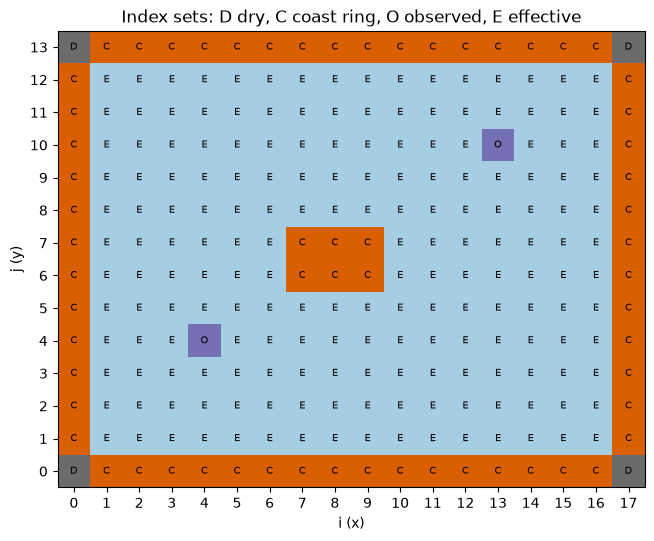

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
cmap = ListedColormap(["#6b6b6b", "#d95f02", "#7570b3", "#a6cee3"])
ax.imshow(labels, origin="lower", cmap=cmap, vmin=-0.5, vmax=3.5)
for j in range(Ny):
    for i in range(Nx):
        ax.text(i, j, "DCOE"[labels[j, i]], ha="center", va="center", fontsize=7)
ax.set_xticks(range(Nx))
ax.set_yticks(range(Ny))
ax.set_xlabel("i (x)")
ax.set_ylabel("j (y)")
ax.set_title("Index sets: D dry, C coast ring, O observed, E effective")
plt.tight_layout()
plt.show()

The coast ring $C$ is dry: it wraps **both** the outer walls and the island, one cell outside the water (the array corners and the island's corners are not on it: no wet cell is 4-adjacent to them).  The observations $O$ sit inside the wet domain.  The light-blue cells $E$ — all the other wet cells — are solved for.


### 2.3 The linear system and its block structure

Order the cells of $E \cup K$ as $[E, K]$ and write the stencil restricted to them as a matrix $A$.  The equations at the effective cells read

$$ \begin{pmatrix} A_{EE} & A_{EK} \end{pmatrix} \begin{pmatrix} \psi_E \\ \psi_K \end{pmatrix} = f_E . $$

At the known cells we do **not** impose the PDE; we impose the data, $\psi_K = g_K$.  Moving the known part to the right-hand side gives the system that is actually solved:

$$ \boxed{\;A_{EE}\,\psi_E = f_E - A_{EK}\, g_K\;} $$

This is block elimination of known unknowns — nothing is approximated. The correction $A_{EK} g_K$ is non-zero only at effective cells that touch a known cell.  For example, at an effective cell whose **south** neighbour is on the coast:

```
           psi[j+1, i]                    (E, unknown)
                |
psi[j, i-1] -- psi[j, i] -- psi[j, i+1]   (E, unknowns)
                |
           g[j-1, i]                      (C, dry: data -> moved to RHS)

  rhs_corrected[j, i] = f[j, i] - g[j-1, i] / dy^2
```

With $g = 0$ the correction vanishes and $A_{EE}$ is exactly `masked_laplacian` on $E$: **the homogeneous solve is the $g = 0$ case**, with no change of domain.

Two structural facts matter for choosing a solver:

* $A$ is **symmetric** ($a_{cd} = a_{dc}$: both are $1/h^2$ for neighbours).
* $A_{EE}$ is **negative definite** for $\lambda \ge 0$: it is a discrete Laplacian with Dirichlet points on its boundary, hence irreducibly diagonally dominant with negative diagonal.  So $-A_{EE}$ is symmetric positive definite — exactly what conjugate gradients needs — and it is invertible even for $\lambda = 0$.

Let us build $A$ densely on the small grid and look at it.


A symmetric:            True
A_EE eigenvalues < 0:   True
cond(A_EE) = 23.0


A_EE == masked_laplacian on E: True


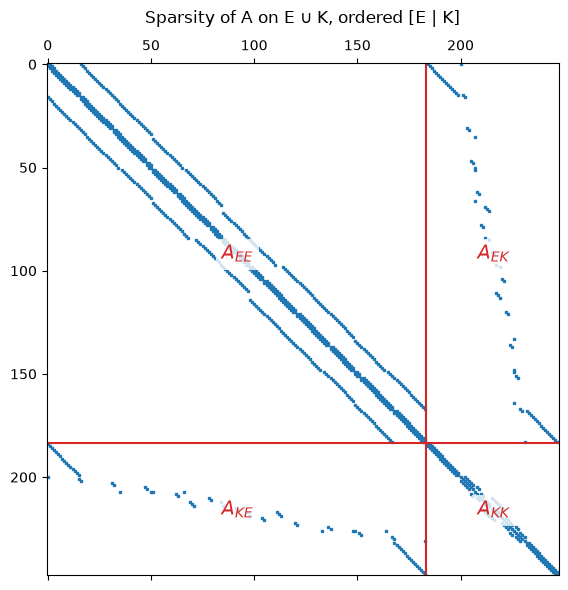

In [6]:
dx_s, dy_s, lam_s = 0.3, 0.25, 2.0


def dense_operator(mask, dx, dy, lam):
    """Dense 5-point (A - lambda) restricted to the mask's cells, with an index map.

    A[k, k]    = -2/dx^2 - 2/dy^2 - lambda
    A[k, nbr]  = 1/dx^2 (east/west),  1/dy^2 (north/south)  for neighbours in mask
    """
    cells = np.argwhere(mask > 0.5)
    index = {tuple(c): k for k, c in enumerate(cells)}
    A = np.zeros((len(cells), len(cells)))
    for k, (j, i) in enumerate(cells):
        # A[(j,i), (j,i)] = -2/dx^2 - 2/dy^2 - lambda
        A[k, k] = -2.0 / dx**2 - 2.0 / dy**2 - lam
        # Off-diagonal entries, one per neighbour in the mask:
        #   A[(j,i), (j,i+1)] = 1/dx^2   (east)
        #   A[(j,i), (j,i-1)] = 1/dx^2   (west)
        #   A[(j,i), (j+1,i)] = 1/dy^2   (north)
        #   A[(j,i), (j-1,i)] = 1/dy^2   (south)
        for dj, di, h in ((0, 1, dx), (0, -1, dx), (1, 0, dy), (-1, 0, dy)):
            nbr = (j + dj, i + di)
            if nbr in index:
                A[k, index[nbr]] += 1.0 / h**2
    return A, cells


# A over E | K (the coast cells are dry, but they carry the data)
A, cells = dense_operator((E | K).astype(float), dx_s, dy_s, lam_s)
is_known = np.array([K[j, i] for j, i in cells])
order = np.concatenate([np.where(~is_known)[0], np.where(is_known)[0]])
A_ord = A[np.ix_(order, order)]
nE = int((~is_known).sum())

A_EE = A[np.ix_(~is_known, ~is_known)]
print(f"A symmetric:            {np.allclose(A, A.T)}")
print(f"A_EE eigenvalues < 0:   {np.all(np.linalg.eigvalsh(A_EE) < 0)}")
print(f"cond(A_EE) = {np.linalg.cond(A_EE):.1f}")

# A_EE is masked_laplacian on E (dry neighbours read as zero).
eff_j = jnp.asarray(E, dtype=float)
cols = []
for k in range(nE):
    e_k = np.zeros((Ny, Nx))
    e_k[tuple(cells[~is_known][k])] = 1.0
    out = gridax.solvers.masked_laplacian(
        jnp.asarray(e_k), eff_j, dx_s, dy_s, lambda_=lam_s
    )
    cols.append(np.asarray(out)[tuple(cells[~is_known].T)])
print(f"A_EE == masked_laplacian on E: {np.allclose(np.stack(cols, axis=1), A_EE)}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.spy(A_ord, markersize=1.5)
ax.axhline(nE - 0.5, color="C3")
ax.axvline(nE - 0.5, color="C3")
nK = len(order) - nE
for label, (row, col) in {
    "$A_{EE}$": (nE / 2, nE / 2),
    "$A_{EK}$": (nE / 2, nE + nK / 2),
    "$A_{KE}$": (nE + nK / 2, nE / 2),
    "$A_{KK}$": (nE + nK / 2, nE + nK / 2),
}.items():
    ax.text(
        col,
        row,
        label,
        color="C3",
        fontsize=14,
        ha="center",
        va="center",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
ax.set_title("Sparsity of A on E ∪ K, ordered [E | K]", pad=12)
plt.tight_layout()
plt.show()

The top-left block is $A_{EE}$ (what the solver inverts); the top-right block $A_{EK}$ is the coupling that becomes the right-hand-side correction.  The bottom rows are never used: at known cells the equation is replaced by $\psi = g$.


---

## Part 3 — From scratch

### 3.1 Pseudocode

The algorithm has an **offline** half (depends only on the mask; done once) and an **online** half (depends on $f$ and $g$; done every solve, e.g. every time step).

```
OFFLINE — once per mask
  W[j,i] <- mask[j,i] > 0.5                                   # wet cells
  C[j,i] <- not W[j,i] and (W[j+1,i] or W[j-1,i]
                             or W[j,i+1] or W[j,i-1])         # coast ring (dry)
  O[j,i] <- known_mask[j,i] and W[j,i]                        # observations
  K[j,i] <- C[j,i] or O[j,i]                                  # known cells
  E[j,i] <- W[j,i] and not O[j,i]                             # unknowns
  S      <- solver for  A_EE x = b                            # CG / spectral / ...

ONLINE — every solve, given f and g
  lift[j,i] <- g[j,i] if K[j,i] else 0                        # the crude lift
  (A lift)[j,i] = (lift[j,i+1] - 2 lift[j,i] + lift[j,i-1]) / dx^2
                + (lift[j+1,i] - 2 lift[j,i] + lift[j-1,i]) / dy^2
                - lambda lift[j,i]                            # NO mask
  b[j,i]    <- (f[j,i] - (A lift)[j,i]) if E[j,i] else 0     # corrected RHS
  x         <- S(b)                                           # x[j,i] = 0 off E
  psi[j,i]  <- lift[j,i] + x[j,i]
```

The one subtle line is `A lift`: the stencil must be applied **without a mask**, so that it reads the lift on the dry coast cells.  Keeping only the rows in $E$ produces exactly $A_{EK}\, g_K$, because the lift vanishes on $E$.  Part 4 shows what happens if you get the mask wrong.

### 3.2 Implementation in plain NumPy

Nothing below uses the library's lifting code — only a stencil and a dense solve.


In [7]:
def stencil(psi, mask, dx, dy, lam):
    """(A - lambda) applied to psi*mask, output zeroed outside mask (5-point)."""
    # Zero-pad by one cell:  p[j+1, i+1] = (psi * mask)[j, i]
    p = np.pad(psi * mask, 1)
    c = p[1:-1, 1:-1]  # psi[j, i]
    e = p[1:-1, 2:]  # psi[j, i+1]
    w = p[1:-1, :-2]  # psi[j, i-1]
    n = p[2:, 1:-1]  # psi[j+1, i]
    s = p[:-2, 1:-1]  # psi[j-1, i]
    # (A psi)[j, i] = (psi[j, i+1] - 2 psi[j, i] + psi[j, i-1]) / dx^2
    #               + (psi[j+1, i] - 2 psi[j, i] + psi[j-1, i]) / dy^2
    #               - lambda * psi[j, i]
    lap = (e - 2 * c + w) / dx**2 + (n - 2 * c + s) / dy**2
    return (lap - lam * c) * mask


def solve_known_values_numpy(f, g, mask, known_mask, dx, dy, lam):
    """Inhomogeneous Dirichlet solve by lifting — the pseudocode, verbatim."""
    # OFFLINE
    wet = mask > 0.5
    # pw[j+1, i+1] = wet[j, i]  (dry padding outside the array)
    pw = np.pad(wet, 1, constant_values=False)
    # coast[j, i] = dry[j, i] & (wet[j+1, i] | wet[j-1, i] | wet[j, i+1] | wet[j, i-1])
    coast = ~wet & (pw[2:, 1:-1] | pw[:-2, 1:-1] | pw[1:-1, 2:] | pw[1:-1, :-2])
    obs = known_mask & wet
    known = coast | obs
    eff = wet & ~obs
    A_EE, eff_cells = dense_operator(eff.astype(float), dx, dy, lam)
    # ONLINE
    lift = np.where(known, g, 0.0)
    ones = np.ones_like(f)  # no mask: read the lift on the dry coast
    b = (f - stencil(lift, ones, dx, dy, lam)) * eff
    x = np.zeros_like(f)
    x[tuple(eff_cells.T)] = np.linalg.solve(A_EE, b[tuple(eff_cells.T)])
    return lift + x


rng = np.random.default_rng(0)
f_small = rng.standard_normal((Ny, Nx)) * mask_small
g_small = rng.standard_normal((Ny, Nx))

psi_scratch = solve_known_values_numpy(
    f_small, g_small, mask_small, obs_small, dx_s, dy_s, lam_s
)

# Reference 1: block elimination on the full dense matrix (Part 2.3).
f_c = np.array([f_small[j, i] for j, i in cells])
g_c = np.array([g_small[j, i] for j, i in cells])
psi_E = np.linalg.solve(
    A[np.ix_(~is_known, ~is_known)],
    f_c[~is_known] - A[np.ix_(~is_known, is_known)] @ g_c[is_known],
)
psi_block = np.zeros((Ny, Nx))
psi_block[tuple(cells[is_known].T)] = g_c[is_known]
psi_block[tuple(cells[~is_known].T)] = psi_E
diff_block = np.max(np.abs(psi_scratch - psi_block))
print(f"scratch lifting vs block elimination: {diff_block:.2e}")

# The defining properties of the answer (the unmasked stencil reads psi = g on C):
res = f_small - stencil(psi_scratch, np.ones((Ny, Nx)), dx_s, dy_s, lam_s)
print(f"max |psi - g| on K:         {np.max(np.abs((psi_scratch - g_small)[K])):.2e}")
print(f"max |PDE residual| on E:    {np.max(np.abs(res[E])):.2e}")
print(
    f"max |PDE residual| on K:    {np.max(np.abs(res[K])):.2e}   (not zero, by design)"
)

scratch lifting vs block elimination: 1.11e-16
max |psi - g| on K:         0.00e+00
max |PDE residual| on E:    1.80e-14
max |PDE residual| on K:    1.61e+02   (not zero, by design)


Read those three numbers carefully:

* $\psi = g$ **exactly** on the known cells;
* the PDE holds to round-off on the effective cells;
* the PDE does **not** hold on the known cells — there the equation was *replaced* by the data.  This is the defining property of a Dirichlet point, not an error.


---

## Part 4 — Why the *coast* ring?

Every sesmax solver puts its homogeneous wall in the same place: on the dry cells next to water, which `masked_laplacian` reads as $\psi = 0$. For ψ on the C-grid (`Mask2D.xy_corner_strict`) those are the wall nodes — X rows / columns `0` and `N-2` of a rectangle, the nodes that sit on the physical walls $x = 0, L$.  Putting the known values **there** means:

* the data sits on the physical boundary, and the scheme stays second order (Part 7);
* $g = 0$ is *exactly* the homogeneous solve — no change of domain;
* every wet cell remains an unknown.

The alternative some codes use — data on the *wet* cells next to land (the "inner ring", `gridax.solvers.boundary_ring`) — moves the wall one cell into the water: with $g = 0$ it solves a basin one cell smaller, an $O(\Delta x)$ change of the boundary.

Because the data now lives on **dry** cells, two masks appear in the algorithm:

| Step | Mask | Why |
|------|------|-----|
| correction `A lift` | none (all ones) | the stencil must *see* the lift on the dry coast $C$ |
| solve `S(b)` | effective $E$ | observed cells are data, not unknowns |

Using the wet mask $W$ for the correction erases the lift (`masked_laplacian` zeroes dry cells first, so the correction is identically zero); using $W$ for the solve treats the observations as unknowns and overwrites them. All of this is checked below.


In [8]:
def cg(matvec, b, *, preconditioner=None, rtol=1e-6, atol=1e-6, max_steps=500):
    """CG on a negative-definite grid operator; returns (x, gaussx.SolveInfo)."""
    operator = gaussx.as_linear_operator(
        matvec,
        in_structure=jax.ShapeDtypeStruct(b.shape, b.dtype),
        negative_definite=True,
    )
    # gaussx solves (-A) x = -b, so a preconditioner passes -M^-1
    positive = None if preconditioner is None else (lambda r: -preconditioner(r))
    solver = gaussx.CGSolver(rtol=rtol, atol=atol, max_steps=max_steps)
    return gaussx.linear_solve_with_info(
        operator, b, solver=solver, preconditioner=positive
    )


f_j, g_j, m_j = jnp.array(f_small), jnp.array(g_small), jnp.array(mask_small)
obs_j = jnp.array(obs_small)
psi_hom = gfd.streamfunction_from_vorticity(
    f_j, dx_s, dy_s, lambda_=lam_s, method="cg", mask=m_j
)
psi_g0 = gfd.streamfunction_from_vorticity(
    f_j,
    dx_s,
    dy_s,
    lambda_=lam_s,
    method="cg",
    mask=m_j,
    known_values=jnp.zeros_like(g_j),
)
print(f"coast ring, g = 0 vs homogeneous solve: {amax(psi_g0 - psi_hom):.1e}")

# Inner-ring convention: the wet cells next to land become data, so with g = 0
# the solve runs on W minus that ring -- a smaller basin.
R = gridax.solvers.boundary_ring(m_j)
psi_inner = gfd.streamfunction_from_vorticity(
    f_j, dx_s, dy_s, lambda_=lam_s, method="cg", mask=m_j * ~R
)
print(
    f"inner ring, g = 0 vs homogeneous solve: {amax(psi_inner - psi_hom):.1e}"
    f"   (max |psi| = {amax(psi_hom):.2f})"
)

# The coast part of the lift, seen through the wet mask and without a mask.
lift_c = jnp.where(C, g_j, 0.0)
wrong_corr = gridax.solvers.masked_laplacian(lift_c, m_j, dx_s, dy_s, lam_s) * eff_j
print(
    f"coast correction with W-mask: max |correction| = {amax(wrong_corr):.1e}"
    "   <- the lift on the dry coast is erased"
)
right_corr = (
    gridax.solvers.masked_laplacian(lift_c, jnp.ones_like(m_j), dx_s, dy_s, lam_s)
    * eff_j
)
print(
    f"coast correction unmasked:    max |correction| = {amax(right_corr):.1e}"
    "   <- correct"
)

# Solving on W instead of E: the observed cells become unknowns again.
lift_j = jnp.where(K, g_j, 0.0)
b_W = (
    f_j - gridax.solvers.masked_laplacian(lift_j, jnp.ones_like(m_j), dx_s, dy_s, lam_s)
) * m_j
x_W, _ = cg(
    lambda v: gridax.solvers.masked_laplacian(v, m_j, dx_s, dy_s, lambda_=lam_s),
    b_W,
    rtol=1e-12,
    atol=1e-12,
)
psi_W = lift_j + x_W * m_j
print(
    f"solve on W: max |psi - g| on the observations = {amax((psi_W - g_j)[O]):.1e}"
    "   <- data overwritten"
)

coast ring, g = 0 vs homogeneous solve: 0.0e+00


inner ring, g = 0 vs homogeneous solve: 5.8e-02   (max |psi| = 0.10)
coast correction with W-mask: max |correction| = 0.0e+00   <- the lift on the dry coast is erased
coast correction unmasked:    max |correction| = 4.0e+01   <- correct


solve on W: max |psi - g| on the observations = 1.4e+00   <- data overwritten


---

## Part 5 — Solvers for $A_{EE}\,x = b$

The lifting is solver-agnostic: it only needs *some* way to apply $A_{EE}^{-1}$, i.e. to solve the homogeneous problem on $E$ with $\psi = 0$ on everything around it.  What each solver needs to be told:

| Solver | Works on | Build it with | Notes |
|--------|----------|---------------|-------|
| Conjugate gradient | any mask | operator `masked_laplacian(., E)` | $-A_{EE}$ is SPD; iterations $\sim\sqrt{\kappa}$ |
| CG + multigrid preconditioner | any mask | `build_multigrid_solver(E)` with `method="multigrid"` | grid-independent iteration count |
| Spectral (DST) | ψ rectangle only | nothing | $O(N \log N)$, direct |
| Capacitance matrix | any mask, fixed | `build_capacitance_solver(W)` | direct after an $O(N_c)$ setup; no observations |

**Spectral.**  For the rectangle's `Mask2D`, the ψ mask `xy_corner_strict` is wet on `[1:-2, 1:-2]` ($1 \le j \le N_y-3$, $1 \le i \le N_x-3$), its coast is X rows / columns $0$ and $N-2$, and without observations $E = W$ is a rectangle.  $A_{EE}$ is then the Dirichlet Laplacian on a rectangle, diagonalised by the type-I discrete sine transform $S$:

$$ A_{EE} = S^{-1} \Lambda S, \qquad \Lambda_{kl} = -\frac{4}{\Delta x^2}\sin^2\!\frac{\pi k}{2(n_x+1)} -\frac{4}{\Delta y^2}\sin^2\!\frac{\pi l}{2(n_y+1)} - \lambda , $$

with $n = N - 3$ unknowns per direction, so $x = S^{-1}\Lambda^{-1} S\, b$ — exactly, in two FFT-like transforms.

**Capacitance.**  A capacitance solver built on a mask $M$ solves for every cell of $M$ with $\psi = 0$ on $M$'s coast ring — exactly the lifted system when $M = W$ and there are no observations.  Observations would punch holes in $E$ that the precomputed solver does not know about, so capacitance cannot take a `known_mask`.

**Multigrid.**  `gridax.solvers.MultigridSolver` with its default `bc="dirichlet"` uses the same 5-point operator as `masked_laplacian` (a dry neighbour reads as zero), so built on $E$ (not on the wet mask $W$, whose observed cells are data) it solves the lifted system both as the CG preconditioner of `method="multigrid"` and on its own, to the accuracy its V-cycles reach.

The cell below solves one problem five ways on a rectangular basin, where all of them apply.


In [9]:
Nb = 34
dxb = dyb = 1.0 / (Nb - 2)  # 32 x 32 cells on the unit square
lam_b = 4.0
# ocean at T points: 1 <= j, i <= Nb-2; Mask2D gives the psi mask [1:-2, 1:-2]
mask_b = gridax.Mask2D.from_mask(np.pad(np.ones((Nb - 2, Nb - 2), dtype=bool), 1))
f_b = jnp.asarray(np.random.default_rng(1).standard_normal((Nb, Nb)))
g_b = jnp.asarray(np.random.default_rng(2).standard_normal((Nb, Nb)))
dom_b = gridax.solvers.SolveDomain(mask_b)

psi_cg = gfd.streamfunction_from_vorticity(
    f_b, dxb, dyb, lambda_=lam_b, method="cg", mask=mask_b, known_values=g_b
)
psi_spec = gfd.streamfunction_from_vorticity(
    f_b, dxb, dyb, bc="dst", lambda_=lam_b, known_values=g_b
)
cap = gridax.solvers.build_capacitance_solver(mask_b, dxb, dyb, lambda_=lam_b)
psi_cap = gfd.streamfunction_from_vorticity(
    f_b,
    dxb,
    dyb,
    lambda_=lam_b,
    method="capacitance",
    mask=mask_b,
    capacitance_solver=cap,
    known_values=g_b,
)
eff_b = np.asarray(dom_b.effective_mask, dtype=float)
mg = gridax.solvers.build_multigrid_solver(eff_b, dxb, dyb, lambda_=lam_b, n_cycles=10)
psi_mgcg = gfd.streamfunction_from_vorticity(
    f_b,
    dxb,
    dyb,
    lambda_=lam_b,
    method="multigrid",
    mask=mask_b,
    multigrid_solver=mg,
    known_values=g_b,
)
# Standalone multigrid: lift, solve on E, reconstruct
lifter_b = gridax.solvers.KnownValueLifting(dom_b, dxb, dyb, lam_b)
b_b, lift_b = lifter_b.preprocess(f_b, g_b)
psi_mg = lifter_b.postprocess(mg(b_b) * eff_b, lift_b)
for name, psi in [
    ("spectral", psi_spec),
    ("capacitance", psi_cap),
    ("CG + MG", psi_mgcg),
    ("MG (10 V)", psi_mg),
]:
    print(f"{name:12s} vs CG: {amax(psi - psi_cg):.1e}")
print(f"max |psi| = {amax(psi_cg):.2f}   (CG rtol = 1e-6)")

spectral     vs CG: 1.3e-08
capacitance  vs CG: 1.3e-08
CG + MG      vs CG: 1.3e-08
MG (10 V)    vs CG: 1.3e-08
max |psi| = 2.90   (CG rtol = 1e-6)


---

## Part 6 — The sesmax API

### 6.1 One call: `known_values`

The ψ wrappers — [`streamfunction_from_vorticity`](xref:api#sesmax_core.streamfunction_from_vorticity) and [`pv_inversion`](xref:api#sesmax_core.pv_inversion) — live in `sesmax_core.gfd` and accept `known_values`, a full `(Ny, Nx)` field of which only the known cells are read.  ([`pressure_from_divergence`](xref:api#sesmax_core.pressure_from_divergence) refuses them: its T-point Dirichlet wall is on the cell faces, which a value pinned at a cell centre cannot represent.)  The wrapper builds $W, C, K, E$, the lift and the correction, calls the chosen solver on $E$, and adds the lift back.

```python
psi = gfd.streamfunction_from_vorticity(
    zeta, dx, dy, lambda_=lam,
    method="cg", mask=mask,
    known_values=g,            # read on the coast ring (+ known_mask cells)
    known_mask=obs,            # optional interior observations (CG only)
)
```

### 6.2 The building blocks: `SolveDomain` + `KnownValueLifting`

The wrapper is a thin composition of two equinox modules that you can use directly — for a custom solver, or to build the domain once outside a time loop.  They map one-to-one onto the pseudocode:

| Pseudocode | gridax.solvers |
|------------|------------|
| `W, C, K, E` | `domain = gridax.solvers.SolveDomain(mask, known_mask)` |
| `lift`, `b` | `b, lift = gridax.solvers.KnownValueLifting(domain, dx, dy, lam).preprocess(f, g)` |
| `x = S(b)` | *your solver on* `domain.effective_mask` |
| `psi = lift + x` | `psi = lifter.postprocess(x, lift)` |


In [10]:
lifter = gridax.solvers.KnownValueLifting(domain_small, dx_s, dy_s, lam_s)
b, lift = lifter.preprocess(f_j, g_j)

A_eff = lambda x: gridax.solvers.masked_laplacian(x, eff_j, dx_s, dy_s, lambda_=lam_s)
x, info = cg(A_eff, b, rtol=1e-12, atol=1e-12)
psi_blocks = lifter.postprocess(x * eff_j, lift)

psi_wrapper = gfd.streamfunction_from_vorticity(
    f_j,
    dx_s,
    dy_s,
    lambda_=lam_s,
    method="cg",
    mask=m_j,
    known_values=g_j,
    known_mask=obs_j,
)
print(f"CG iterations: {int(info.iterations)}, converged: {bool(info.converged)}")
print(f"building blocks vs NumPy scratch: {amax(psi_blocks - psi_scratch):.1e}")
print(
    f"wrapper         vs NumPy scratch: {amax(psi_wrapper - psi_scratch):.1e}"
    "   (CG rtol = 1e-6)"
)

CG iterations: 59, converged: True
building blocks vs NumPy scratch: 2.6e-14
wrapper         vs NumPy scratch: 3.9e-08   (CG rtol = 1e-6)


### 6.3 Boundary conditions as a `BC`

When the data is "one value per wall", describe it with the same `gridax.BC` used for time stepping and pass it as `bc=`. Non-zero `Dirichlet` values are written onto each face's wall nodes — the coast cells on the row / column just outside the wet cells, X rows / columns `0` and `N-2` of a rectangle (west/east own the shared nodes) — and an all-zero one is the ordinary homogeneous solve.


In [11]:
walls = gridax.BC(
    south=gridax.Dirichlet(0.0),
    north=gridax.Dirichlet(0.2),
    west=gridax.Dirichlet(0.0),
    east=gridax.Dirichlet(-0.1),
)
psi_bc = gfd.streamfunction_from_vorticity(
    f_b, dxb, dyb, lambda_=lam_b, bc=walls, method="cg", mask=mask_b
)
# The north wall is X row N-2 and the east wall X column N-2.
north, east = float(psi_bc[-2, 5]), float(psi_bc[5, -2])
print(f"north wall row: {north:+.3f}   east wall column: {east:+.3f}")

north wall row: +0.200   east wall column: -0.100


### 6.4 What the lift and the correction look like

On a larger basin with an island and a smooth, spatially varying $g$:


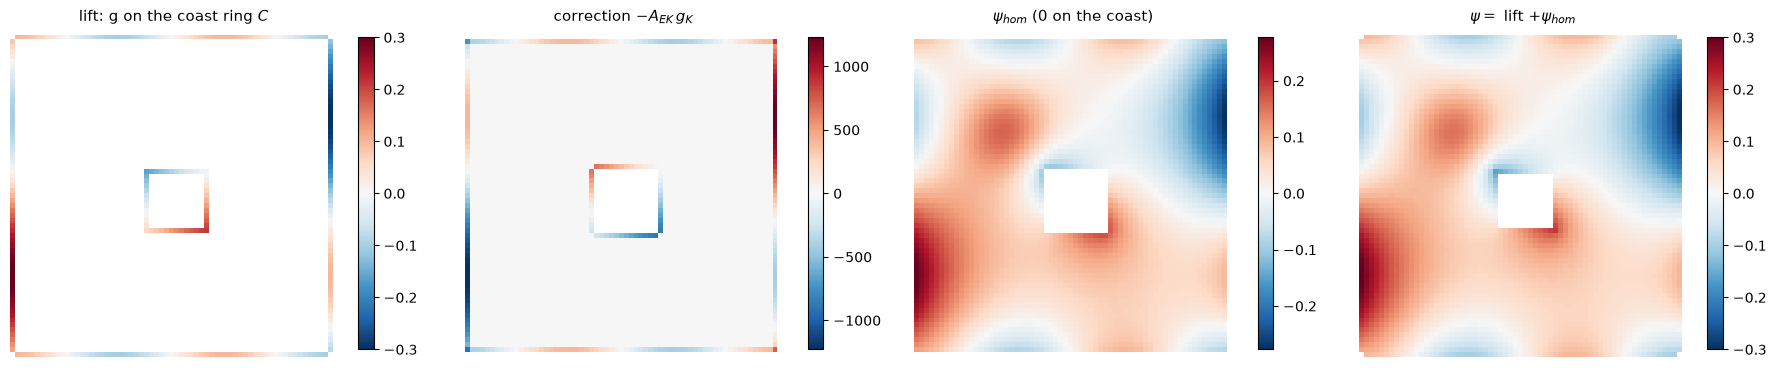

In [12]:
Nd = 66
dxd = dyd = 1.0 / (Nd - 2)  # 64 x 64 cells on the unit square
# ocean at T points: 1 <= j, i <= Nd-2, minus the island 26 <= j <= 37, 28 <= i <= 39
ocean_d = np.pad(np.ones((Nd - 2, Nd - 2), dtype=bool), 1)
ocean_d[26:38, 28:40] = False
mask_d = gridax.Mask2D.from_mask(ocean_d)
# X node (j, i) sits at (x, y) = (i dx, j dy)
yy, xx = jnp.meshgrid(jnp.arange(Nd) * dyd, jnp.arange(Nd) * dxd, indexing="ij")
g_d = 0.2 * jnp.sin(2 * jnp.pi * yy) + 0.1 * jnp.cos(3 * jnp.pi * xx)
f_d = -30.0 * jnp.exp(-((xx - 0.3) ** 2 + (yy - 0.7) ** 2) / 0.01)

dom_d = gridax.solvers.SolveDomain(mask_d)
lifter_d = gridax.solvers.KnownValueLifting(dom_d, dxd, dyd, 1.0)
b_d, lift_d = lifter_d.preprocess(f_d, g_d)
psi_d = gfd.streamfunction_from_vorticity(
    f_d, dxd, dyd, lambda_=1.0, method="cg", mask=mask_d, known_values=g_d
)
hom_d = (psi_d - lift_d) * dom_d.effective_mask

wet_d = np.asarray(dom_d.wet_mask)
shown_d = wet_d | np.asarray(dom_d.coast_ring)
panels = [
    (
        np.where(np.asarray(dom_d.all_known), lift_d, np.nan),
        "lift: g on the coast ring $C$",
    ),
    (
        np.where(np.asarray(dom_d.effective_mask), b_d - f_d, np.nan),
        "correction $-A_{EK}\\,g_K$",
    ),
    (
        np.where(np.asarray(dom_d.effective_mask), hom_d, np.nan),
        "$\\psi_{hom}$ (0 on the coast)",
    ),
    (np.where(shown_d, psi_d, np.nan), "$\\psi = $ lift $+ \\psi_{hom}$"),
]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (field, title) in zip(axes, panels, strict=True):
    vmax = float(np.nanmax(np.abs(field)))  # symmetric: white = 0
    im = ax.imshow(field, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

The correction (second panel) is non-zero only on the single layer of wet cells touching the coast — the rows of $A_{EK}$ are that sparse.


---

## Part 7 — Verification: a manufactured solution

To check the *discretisation*, not just the algebra, take a continuous solution that does **not** vanish on the boundary,

$$ \psi^\star(x, y) = \sin(\pi x)\sin(\pi y) + 0.1\,\sin(2\pi y), \qquad (x, y) \in [0, 1]^2, $$

compute $f = (\nabla^2 - \lambda)\psi^\star$ analytically,

$$ f = -2\pi^2 \sin(\pi x)\sin(\pi y) - 0.4\pi^2 \sin(2\pi y) - \lambda\,\psi^\star , $$

and solve on the C-grid of `from_interior(n, n, 1, 1)`: the arrays are $(n+2)^2$, X node $k$ sits at $x = k h$ with $h = 1/n$, so the wall nodes $k = 0$ and $k = N-2 = n$ are **on** $\partial\Omega$ ($x = 0$ and $x = 1$). Feeding $g = \psi^\star$ there, the error should fall like $h^2$.


n =    8   max error = 1.302e-02
n =   16   max error = 3.238e-03
n =   32   max error = 8.140e-04
n =   64   max error = 2.034e-04
n =  128   max error = 5.085e-05
observed orders: [2.008 1.992 2.001 2.   ]


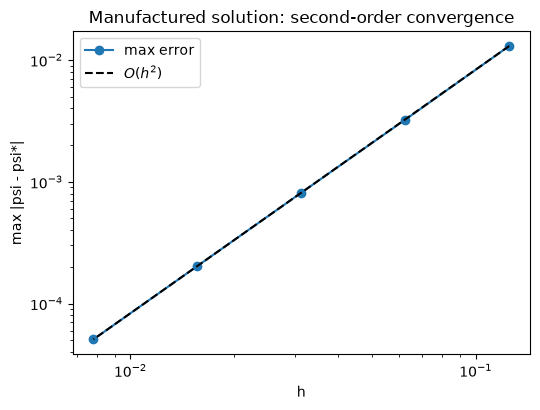

In [13]:
def exact(x, y):
    return np.sin(np.pi * x) * np.sin(np.pi * y) + 0.1 * np.sin(2 * np.pi * y)


def exact_rhs(x, y, lam):
    lap = -2 * np.pi**2 * np.sin(np.pi * x) * np.sin(
        np.pi * y
    ) - 0.4 * np.pi**2 * np.sin(2 * np.pi * y)
    return lap - lam * exact(x, y)


lam_m = 4.0
ns = (8, 16, 32, 64, 128)
hs, errs = [], []
for n in ns:
    h = 1.0 / n
    coord = np.arange(n + 2) * h  # X nodes: wall nodes 0 and n at x = 0, 1
    X, Y = np.meshgrid(coord, coord)
    psi_star = exact(X, Y)
    psi_num = gfd.streamfunction_from_vorticity(
        jnp.array(exact_rhs(X, Y, lam_m)),
        h,
        h,
        bc="dst",
        lambda_=lam_m,
        known_values=jnp.array(psi_star),
    )
    wet = np.zeros_like(psi_star, dtype=bool)
    # wet X nodes: 1 <= j, i <= n-1  ([1:-2, 1:-2])
    wet[1:-2, 1:-2] = True
    hs.append(h)
    errs.append(np.max(np.abs((np.asarray(psi_num) - psi_star)[wet])))

# order[k] = log2( err[k] / err[k+1] )   (h halves between k and k+1)
rates = np.log2(np.array(errs[:-1]) / np.array(errs[1:]))
for n, e in zip(ns, errs, strict=True):
    print(f"n = {n:4d}   max error = {e:.3e}")
print("observed orders:", np.round(rates, 3))

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.loglog(hs, errs, "o-", label="max error")
ax.loglog(hs, errs[0] * (np.array(hs) / hs[0]) ** 2, "k--", label="$O(h^2)$")
ax.set_xlabel("h")
ax.set_ylabel("max |psi - psi*|")
ax.set_title("Manufactured solution: second-order convergence")
ax.legend()
plt.tight_layout()
plt.show()

The observed order is 2: the known-value machinery adds no error of its own — the only error is the 5-point stencil's truncation error.


---

## Part 8 — In practice

### 8.1 Interior observations (`known_mask`)

Nothing in Part 2 required $K$ to lie on the boundary.  Marking interior cells as known turns observations into internal Dirichlet points: the solution passes through them exactly and the PDE holds everywhere else. (This is a *hard* constraint; a weighted, noisy-observation version would instead add a penalty term.)


psi at gauges: [0.4, 0.4, 0.4, 0.4]


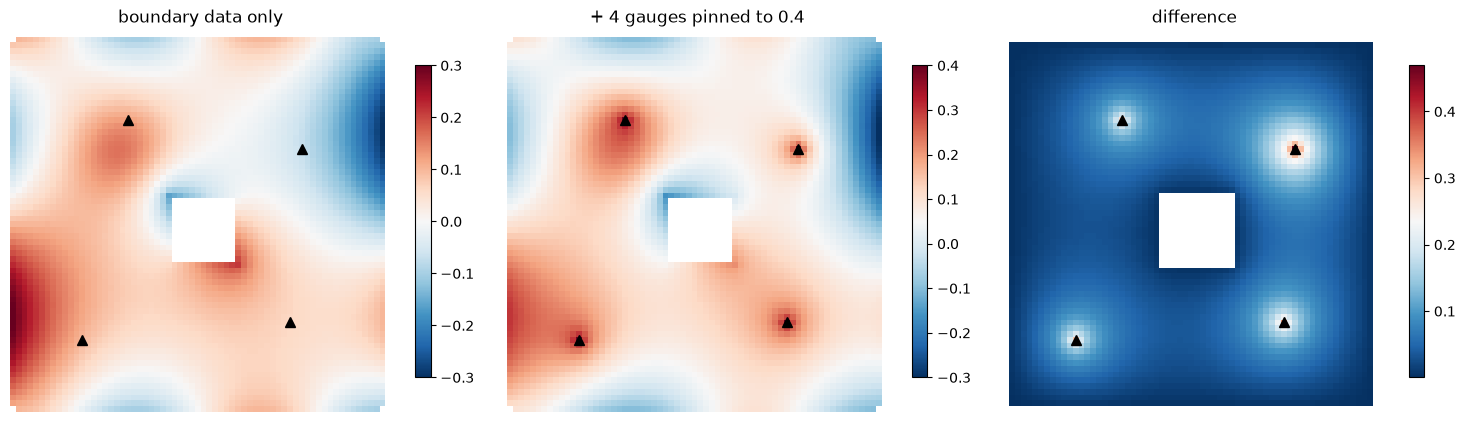

In [14]:
obs_d = jnp.zeros((Nd, Nd), dtype=bool)
gauges = [(12, 12), (50, 20), (45, 50), (15, 48)]
values_d = g_d
for j, i in gauges:
    obs_d = obs_d.at[j, i].set(True)
    values_d = values_d.at[j, i].set(0.4)
assert all(bool(dom_d.wet_mask[j, i]) for j, i in gauges)

psi_obs = gfd.streamfunction_from_vorticity(
    f_d,
    dxd,
    dyd,
    lambda_=1.0,
    method="cg",
    mask=mask_d,
    known_values=values_d,
    known_mask=obs_d,
)
print("psi at gauges:", [round(float(psi_obs[j, i]), 6) for j, i in gauges])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
diff = np.where(wet_d, psi_obs - psi_d, np.nan)
for ax, field, title in [
    (axes[0], np.where(shown_d, psi_d, np.nan), "boundary data only"),
    (axes[1], np.where(shown_d, psi_obs, np.nan), "+ 4 gauges pinned to 0.4"),
    (axes[2], diff, "difference"),
]:
    im = ax.imshow(field, origin="lower", cmap="RdBu_r")
    ax.plot([i for _, i in gauges], [j for j, _ in gauges], "k^", ms=7)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### 8.2 Multi-layer PV inversion

In QG models each vertical mode $k$ has its own $\lambda_k = 1/L_{d,k}^2$. A subtle point: $\lambda$ enters $A$ only on the **diagonal**, and the lift is **zero on $E$**, so the correction $A_{EK}\, g_K$ is the same for every $\lambda$.  What changes from layer to layer is the matrix being inverted, $A_{EE}(\lambda_k)$.  sesmax runs the per-layer lift-and-solve inside a `vmap`; `known_values` broadcasts against `pv` — a `(Ny, Nx)` field is shared by all layers, `(nl, Ny, Nx)` gives each layer its own data.


In [15]:
corr = [
    gridax.solvers.KnownValueLifting(dom_d, dxd, dyd, lam).preprocess(f_d, g_d)[0]
    - f_d * dom_d.effective_mask
    for lam in (0.0, 100.0)
]
print(f"correction(lambda=0) - correction(lambda=100): {amax(corr[0] - corr[1]):.1e}")

lambdas = jnp.array([0.0, 10.0, 100.0, 1000.0])
# pv = 0 isolates the response to the boundary data alone.
pv = jnp.zeros((len(lambdas), Nd, Nd))
psi_layers = gfd.pv_inversion(
    pv, dxd, dyd, lambda_=lambdas, method="cg", mask=mask_d, known_values=g_d
)
coast_d = dom_d.coast_ring
for k, lam_k in enumerate(lambdas):
    print(
        f"layer {k}: lambda = {float(lam_k):7.1f}   coast exact: "
        f"{bool(jnp.allclose(psi_layers[k][coast_d], g_d[coast_d]))}   "
        f"psi at (16, 16) = {float(psi_layers[k][16, 16]):+.4f}"
    )

correction(lambda=0) - correction(lambda=100): 0.0e+00


layer 0: lambda =     0.0   coast exact: True   psi at (16, 16) = +0.0760
layer 1: lambda =    10.0   coast exact: True   psi at (16, 16) = +0.0619
layer 2: lambda =   100.0   coast exact: True   psi at (16, 16) = +0.0173
layer 3: lambda =  1000.0   coast exact: True   psi at (16, 16) = +0.0001


With no interior forcing, $\psi$ is driven by the boundary data alone. Larger $\lambda$ **screens** that data: its influence decays over a distance $\sim \lambda^{-1/2}$ from the walls, so the interior value at $(16, 16)$ — about 15 cells from the nearest wall — shrinks towards zero.

### 8.3 Time-varying boundary data inside `jax.jit`

In a nested or data-driven model $g$ changes every step.  Everything in the online half is plain `jax.numpy`, so the whole solve compiles once and is re-run with new data.


In [16]:
@jax.jit
def solve_step(f, g):
    return gfd.streamfunction_from_vorticity(
        f, dxd, dyd, lambda_=1.0, method="cg", mask=mask_d, known_values=g
    )


for t in range(3):
    g_t = g_d * jnp.cos(0.5 * t)
    psi_t = solve_step(f_d, g_t)
    ok = bool(jnp.allclose(psi_t[coast_d], g_t[coast_d]))
    print(f"t = {t}:  coast matches g(t): {ok}")

t = 0:  coast matches g(t): True
t = 1:  coast matches g(t): True
t = 2:  coast matches g(t): True


### 8.4 Gradients with respect to the boundary data

The map $g \mapsto \psi$ is linear, and JAX differentiates straight through the lifting and the solver.  Take the value at one interior point, $J(g) = \psi_{17,10}$ on a 32-cell square with $f = 0$, using the spectral path (the rectangle's ψ basin, wall nodes on rows / columns `0` and `N-2`).  Then $\partial J / \partial g$ is the **discrete harmonic measure** of that point: non-negative weights on the coast saying how much each boundary value contributes.  For $\lambda = 0$ they must sum to 1 (a constant $g \equiv c$ gives $\psi \equiv c$), and for $\lambda > 0$ they sum to less than 1 — screening again.


lambda =   0.0:  sum of weights on coast = 1.000000, min = 5.50e-04, off-coast max |w| = 0.0e+00
lambda =  50.0:  sum of weights on coast = 0.156435, min = 2.14e-05, off-coast max |w| = 0.0e+00


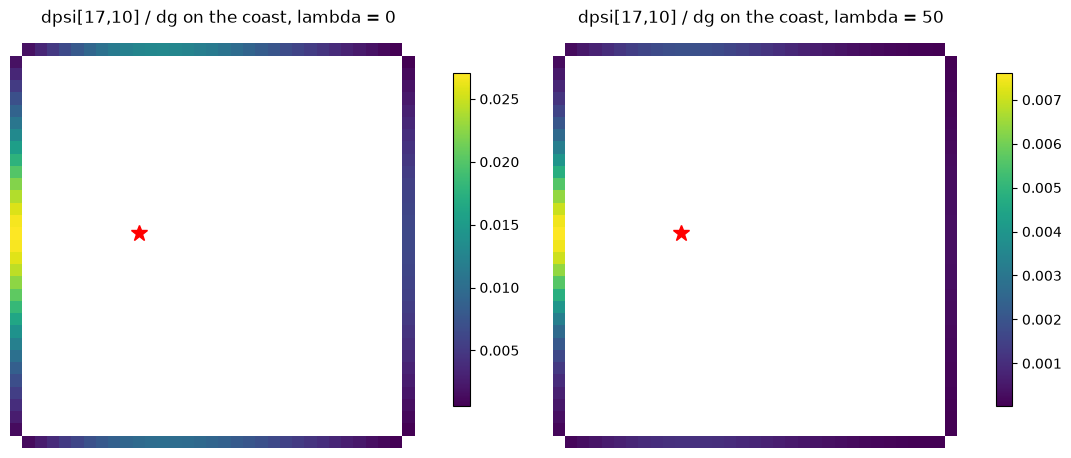

In [17]:
Nh = 34
hh = 1.0 / (Nh - 2)
# psi (X) basin of the rectangle: wet on [1:-2, 1:-2]; its coast is the wall nodes
coast_h = gridax.solvers.coast_ring(jnp.zeros((Nh, Nh)).at[1:-2, 1:-2].set(1.0))


def point_value(g, lam):
    psi = gfd.streamfunction_from_vorticity(
        jnp.zeros((Nh, Nh)), hh, hh, bc="dst", lambda_=lam, known_values=g
    )
    return psi[17, 10]


weights = {}
for lam in (0.0, 50.0):
    wgt = jax.grad(point_value)(jnp.zeros((Nh, Nh)), lam)
    weights[lam] = wgt
    on_coast = wgt[coast_h]
    print(
        f"lambda = {lam:5.1f}:  sum of weights on coast = "
        f"{float(on_coast.sum()):.6f}, min = {float(on_coast.min()):.2e}, "
        f"off-coast max |w| = {amax(wgt[~coast_h]):.1e}"
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, lam in zip(axes, (0.0, 50.0), strict=True):
    wgt = np.where(np.asarray(coast_h), np.asarray(weights[lam]), np.nan)
    im = ax.imshow(wgt, origin="lower", cmap="viridis")
    ax.plot(10, 17, "r*", ms=12)
    ax.set_title(f"dpsi[17,10] / dg on the coast, lambda = {lam:g}")
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

Two details worth noticing:

* The weights are **non-negative** (a discrete maximum principle) and concentrate on the walls nearest the point.
* Only coast nodes carry weight: the four corners of the frame are not on the coast (no wet node is 4-adjacent to them), so the stencil never reads them and their data cannot influence the solution.

This is the same object a data-assimilation system needs to push an interior misfit back onto the boundary data — obtained here for free from `jax.grad`.


---

## Part 9 — Pitfalls checklist

| Symptom | Cause | Fix |
|---------|-------|-----|
| Solution ignores the boundary data | Correction computed with `masked_laplacian(lift, W)`: the mask erases the lift on the dry coast | Apply the stencil unmasked; `KnownValueLifting` does |
| Observations overwritten | Solver built on the wet mask instead of $E$ | CG / multigrid operators on `domain.effective_mask` |
| Wall one cell inside the basin | Data put on the wet cells next to land (`boundary_ring`) | Put it on the coast ring; `known_values` reads only `coast_ring` and `known_mask` cells |
| ψ wall in the wrong place | A T-point mask passed for ψ | Pass a `Mask2D` (its strict X mask is the ψ mask) |
| Capacitance + observations raises | Its unknowns are fixed by the mask it was built on | Use `method="cg"` |
| Spectral solve raises with a mask | The spectral path is the rectangular basin only | Use `method="cg"` / `"capacitance"` for other masks |
| Known values raise for `pressure_from_divergence` | A T-point Dirichlet wall is on the cell faces; the lift pins cell centres (the ghost cells, half a cell out) | Solve for ψ, or prescribe pressure through the right-hand side |
| Non-zero `Dirichlet` faces raise on a `Mask2D` | Its outer coast is not on the four walls | Pass `known_values` on `gridax.solvers.coast_ring(mask)` |
| PDE residual non-zero on the coast | Known cells carry data, not the equation | Expected — check the residual on $E$ only |
| Sign surprises | The operator is $(\nabla^2 - \lambda)$, $\lambda \ge 0$ | Use positive $\lambda = 1/L_d^2$ for screening |

## Summary

* A non-zero Dirichlet boundary is the same problem as a zero one with a corrected right-hand side: $A_{EE}\,\psi_E = f_E - A_{EK}\, g_K$.
* On a grid the lift can be "data on the known cells, zero elsewhere"; the elimination is exact, and accuracy is set by the stencil alone (second order).
* Keep the data on the **coast ring** — the dry cells where every solver puts its wall (for ψ, the C-grid wall nodes) — apply the correction **unmasked**, and solve on the **effective** mask (every wet cell that is not an observation).
* sesmax packages this as `known_values` / `known_mask` on the ψ wrappers, `bc=gridax.BC(...)` for per-wall values, and gridax's `SolveDomain` + `KnownValueLifting` for your own solvers — all JIT-compatible and differentiable.
